# Stage 3 — Image Quality Analysis

This notebook contains the original quality-analysis cells for brightness, contrast, sharpness, retinal-region quality checks, excluded-image inspection, and sample visualizations.

**Important:** this is image-quality analysis/EDA, not a trained Gradable-vs-Ungradable quality-assessment model.

**Original outputs are preserved. Cells have not been executed or modified.**

In [ ]:
######################################################
#stage 7

In [64]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from pathlib import Path

# Dataset paths
BASE_DIR = Path("/kaggle/working/DR_Prepared")
IMAGES_DIR = BASE_DIR / "images"
CSV_PATH = BASE_DIR / "prepared_dataset.csv"

# Output directory
QUALITY_DIR = BASE_DIR / "Quality_Assessment"
QUALITY_DIR.mkdir(parents=True, exist_ok=True)

# Load prepared dataset
df_quality = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully")
print("Total images:", len(df_quality))
print("Columns:", df_quality.columns.tolist())
print("Images directory exists:", IMAGES_DIR.exists())
print("Output directory:", QUALITY_DIR)

Dataset loaded successfully
Total images: 35126
Columns: ['image_path', 'original_path', 'level']
Images directory exists: True
Output directory: /kaggle/working/DR_Prepared/Quality_Assessment


In [65]:
print("Dataset shape:", df_quality.shape)

display(df_quality.head())

print("\nMissing values:")
display(df_quality.isnull().sum())

print("\nClass distribution:")
display(df_quality["level"].value_counts().sort_index())

print("\nImage path example:")
print(df_quality["image_path"].iloc[0])

Dataset shape: (35126, 3)


,image_path,original_path,level
0,/kaggle/working/DR_Prepared/images/image_00000...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0
1,/kaggle/working/DR_Prepared/images/image_00000...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0
2,/kaggle/working/DR_Prepared/images/image_00000...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0
3,/kaggle/working/DR_Prepared/images/image_00000...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0
4,/kaggle/working/DR_Prepared/images/image_00000...,/kaggle/input/datasets/sovitrath/diabetic-reti...,1



Missing values:


image_path       0
original_path    0
level            0
dtype: int64


Class distribution:


level
0    25810
1     2443
2     5292
3      873
4      708
Name: count, dtype: int64


Image path example:
/kaggle/working/DR_Prepared/images/image_000000.jpg


In [66]:
def calculate_image_quality(image_path):

    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray)

    contrast = np.std(gray)

    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness
    }


quality_results = []

for _, row in tqdm(
    df_quality.iterrows(),
    total=len(df_quality),
    desc="Analyzing image quality"
):

    result = calculate_image_quality(row["image_path"])

    if result is not None:

        quality_results.append({
            "image_path": row["image_path"],
            "level": row["level"],
            **result
        })


quality_df = pd.DataFrame(quality_results)

print("Successfully analyzed:", len(quality_df))
print("Failed images:", len(df_quality) - len(quality_df))

display(quality_df.head())

Analyzing image quality:   0%|          | 0/35126 [00:00<?, ?it/s]

Successfully analyzed: 35126
Failed images: 0


,image_path,level,brightness,contrast,sharpness
0,/kaggle/working/DR_Prepared/images/image_00000...,0,56.916554,65.877833,846.268515
1,/kaggle/working/DR_Prepared/images/image_00000...,0,24.773178,28.206603,133.262058
2,/kaggle/working/DR_Prepared/images/image_00000...,0,57.678392,50.117958,505.709521
3,/kaggle/working/DR_Prepared/images/image_00000...,0,58.288724,50.118056,465.803157
4,/kaggle/working/DR_Prepared/images/image_00000...,1,60.970663,61.771409,472.544065


In [67]:
quality_columns = [
    "brightness",
    "contrast",
    "sharpness"
]

display(
    quality_df[quality_columns].describe().round(3)
)

,brightness,contrast,sharpness
count,35126.000,35126.000,35126.000
mean,62.679,50.742,349.901
std,27.211,15.873,271.526
min,1.887,1.656,1.205
25%,42.347,39.269,174.691
50%,58.074,50.354,270.799
75%,79.513,61.734,437.068
max,192.128,123.926,3352.707


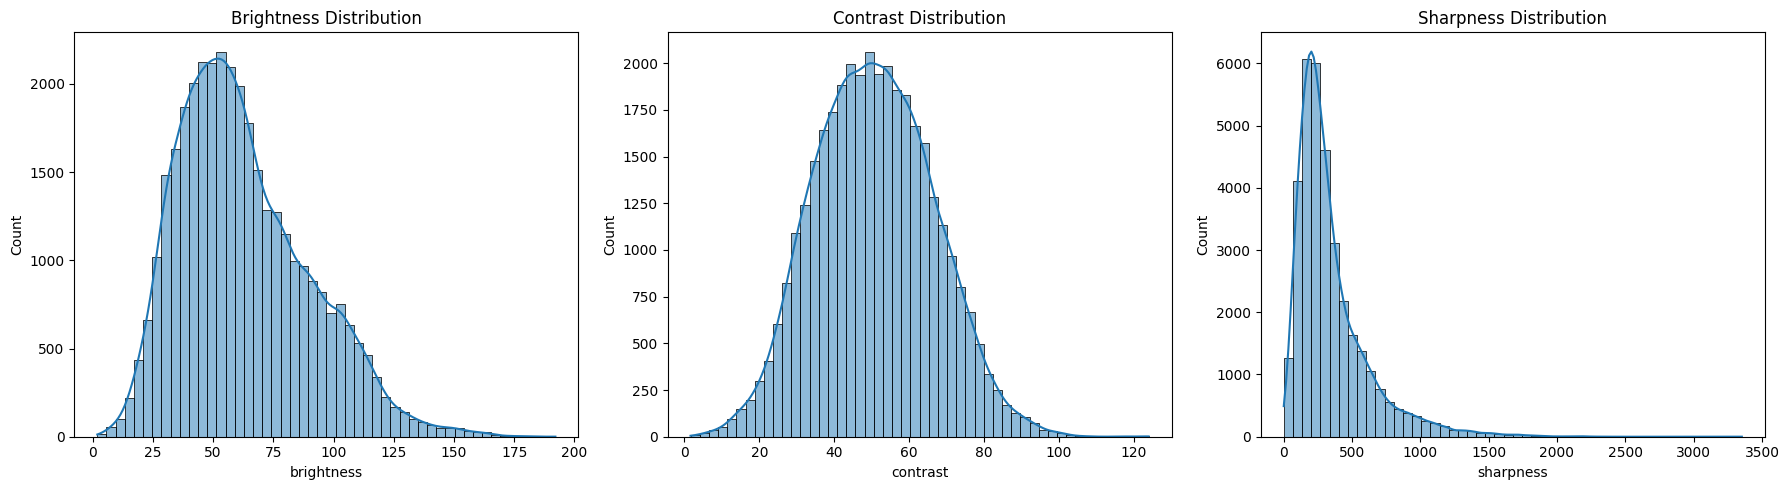

In [68]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, quality_columns):

    sns.histplot(
        data=quality_df,
        x=column,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_title(f"{column.capitalize()} Distribution")

plt.tight_layout()
plt.show()

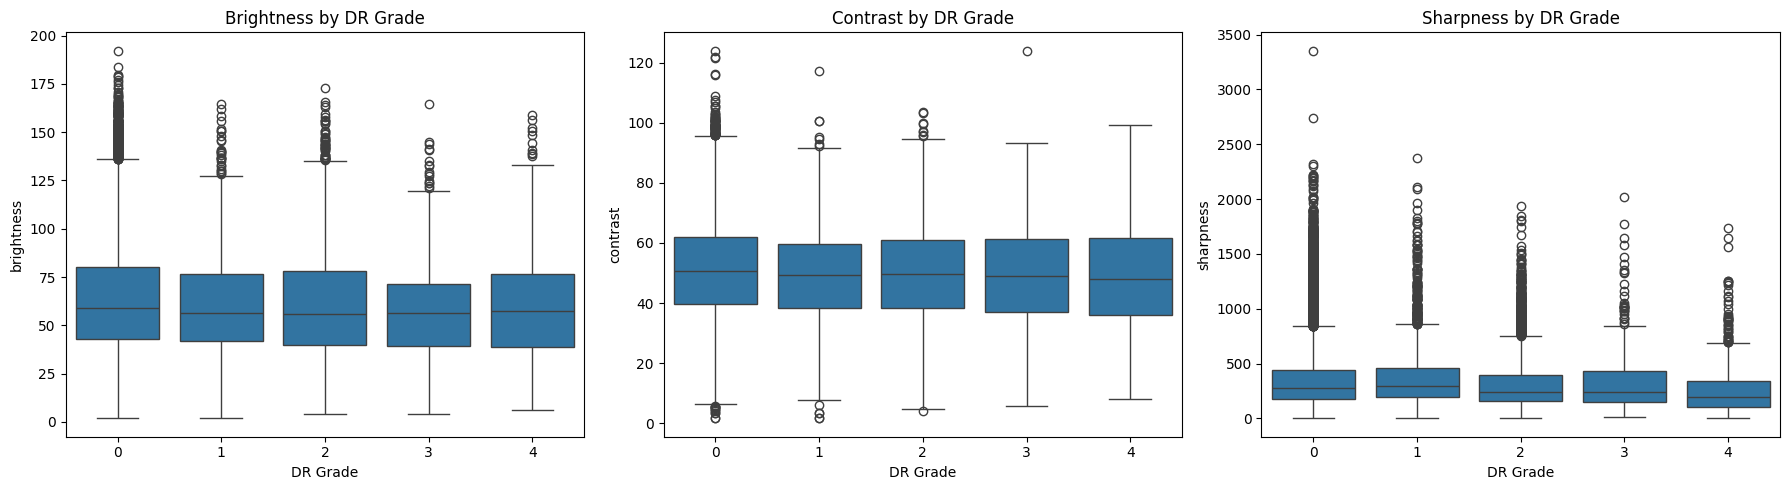

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, quality_columns):

    sns.boxplot(
        data=quality_df,
        x="level",
        y=column,
        ax=ax
    )

    ax.set_title(f"{column.capitalize()} by DR Grade")
    ax.set_xlabel("DR Grade")

plt.tight_layout()
plt.show()

In [70]:
quality_csv_path = QUALITY_DIR / "image_quality_report.csv"

quality_df.to_csv(
    quality_csv_path,
    index=False
)

print("Quality report saved at:")
print(quality_csv_path)

Quality report saved at:
/kaggle/working/DR_Prepared/Quality_Assessment/image_quality_report.csv


In [71]:
def calculate_retina_quality(image_path):
    image = cv2.imread(str(image_path))

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Exclude most of the black background
    mask = gray > 10

    if np.sum(mask) == 0:
        return None

    retina_pixels = gray[mask]

    # Brightness and contrast inside foreground region
    brightness = np.mean(retina_pixels)
    contrast = np.std(retina_pixels)

    # Sharpness inside foreground region
    laplacian = cv2.Laplacian(gray, cv2.CV_64F)
    sharpness = np.var(laplacian[mask])

    foreground_ratio = np.mean(mask)

    return {
        "brightness": brightness,
        "contrast": contrast,
        "sharpness": sharpness,
        "foreground_ratio": foreground_ratio
    }


retina_quality_results = []

for _, row in tqdm(
    df_quality.iterrows(),
    total=len(df_quality)
):
    result = calculate_retina_quality(row["image_path"])

    if result is not None:
        result["image_path"] = row["image_path"]
        result["level"] = row["level"]

        retina_quality_results.append(result)


retina_quality_df = pd.DataFrame(retina_quality_results)

display(
    retina_quality_df[
        ["brightness", "contrast", "sharpness", "foreground_ratio"]
    ].describe().round(3)
)

retina_quality_df.to_csv(
    QUALITY_DIR / "retina_quality_report.csv",
    index=False
)

print("Saved retina-aware quality report successfully.")
print("Processed:", len(retina_quality_df))

  0%|          | 0/35126 [00:00<?, ?it/s]

,brightness,contrast,sharpness,foreground_ratio
count,35123.000,35123.000,35123.000,35123.000
mean,99.382,26.057,450.198,0.624
std,34.262,8.678,325.913,0.134
min,11.000,0.000,4.355,0.000
25%,74.054,20.154,226.855,0.475
50%,98.045,25.470,359.208,0.666
75%,123.083,30.965,585.987,0.745
max,252.065,99.071,3539.625,1.000


Saved retina-aware quality report successfully.
Processed: 35123


In [72]:
# Find images that were not included in retina_quality_df

processed_paths = set(retina_quality_df["image_path"])

excluded_images = df_quality[
    ~df_quality["image_path"].isin(processed_paths)
]

print("Excluded images:", len(excluded_images))

display(excluded_images)

Excluded images: 3


,image_path,original_path,level
1578,/kaggle/working/DR_Prepared/images/image_00157...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0
25497,/kaggle/working/DR_Prepared/images/image_02549...,/kaggle/input/datasets/sovitrath/diabetic-reti...,1
27406,/kaggle/working/DR_Prepared/images/image_02740...,/kaggle/input/datasets/sovitrath/diabetic-reti...,0


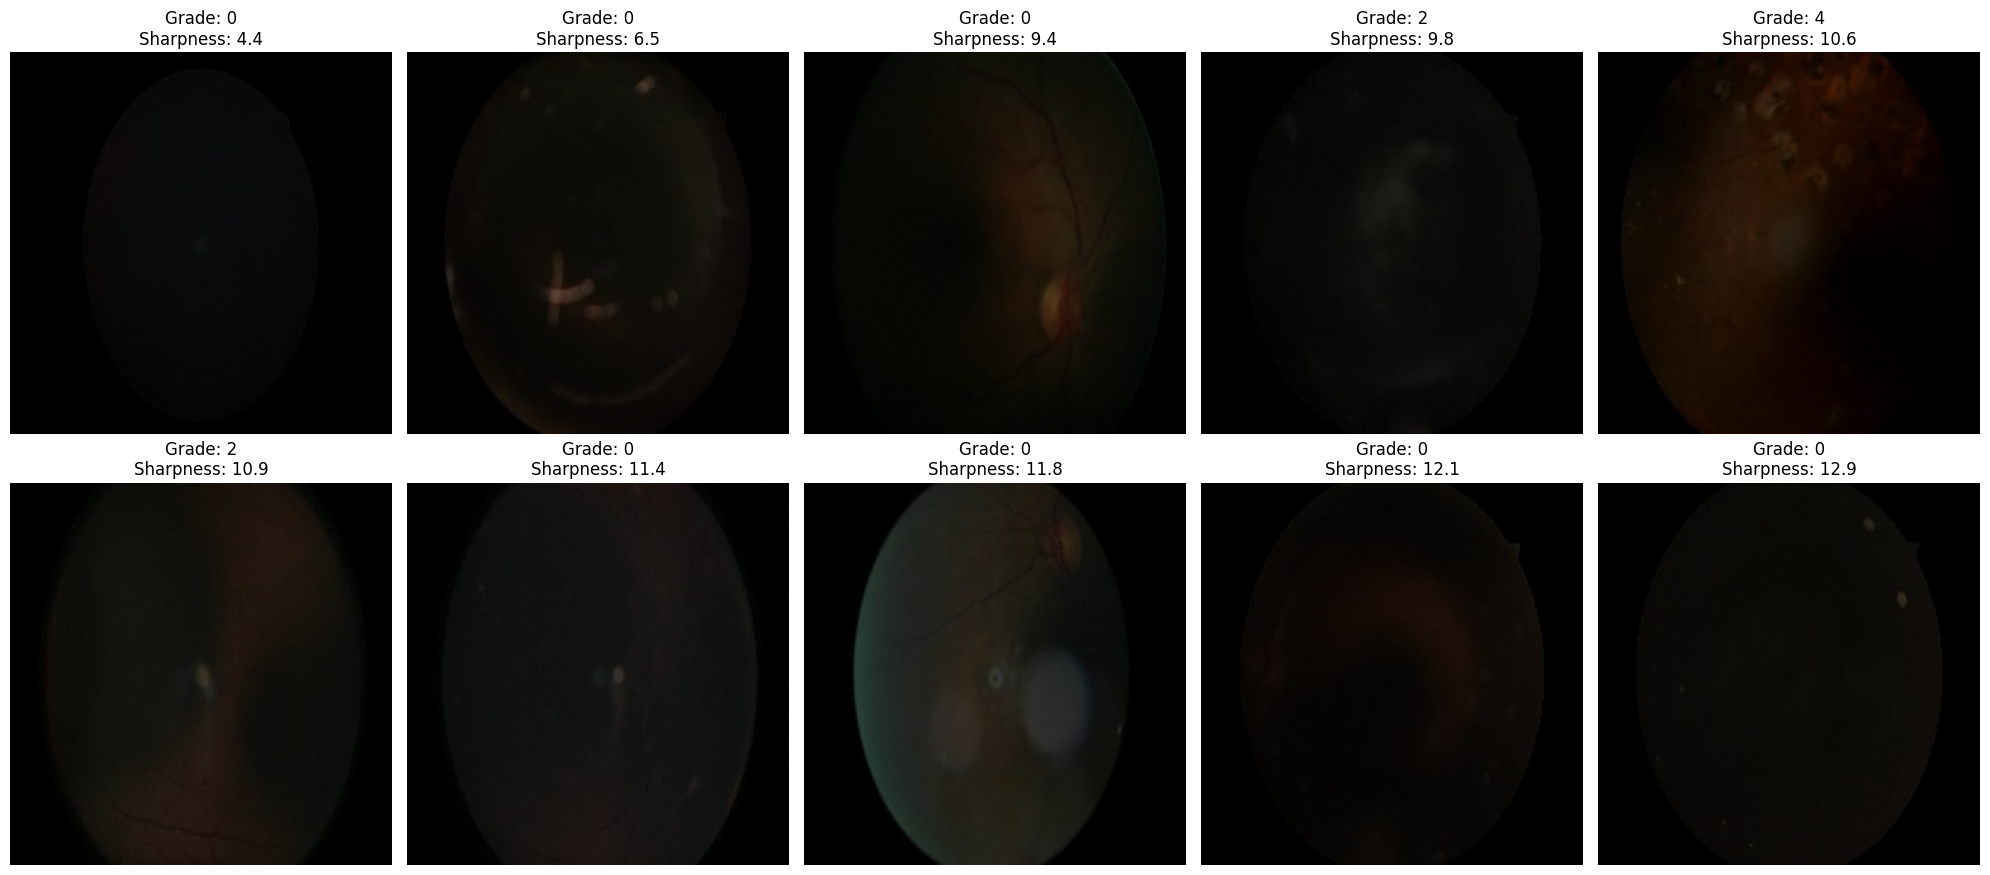

In [73]:
import matplotlib.pyplot as plt

lowest_sharpness = retina_quality_df.nsmallest(10, "sharpness")

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for ax, (_, row) in zip(axes.flat, lowest_sharpness.iterrows()):

    image = cv2.imread(str(row["image_path"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(
        f"Grade: {row['level']}\n"
        f"Sharpness: {row['sharpness']:.1f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

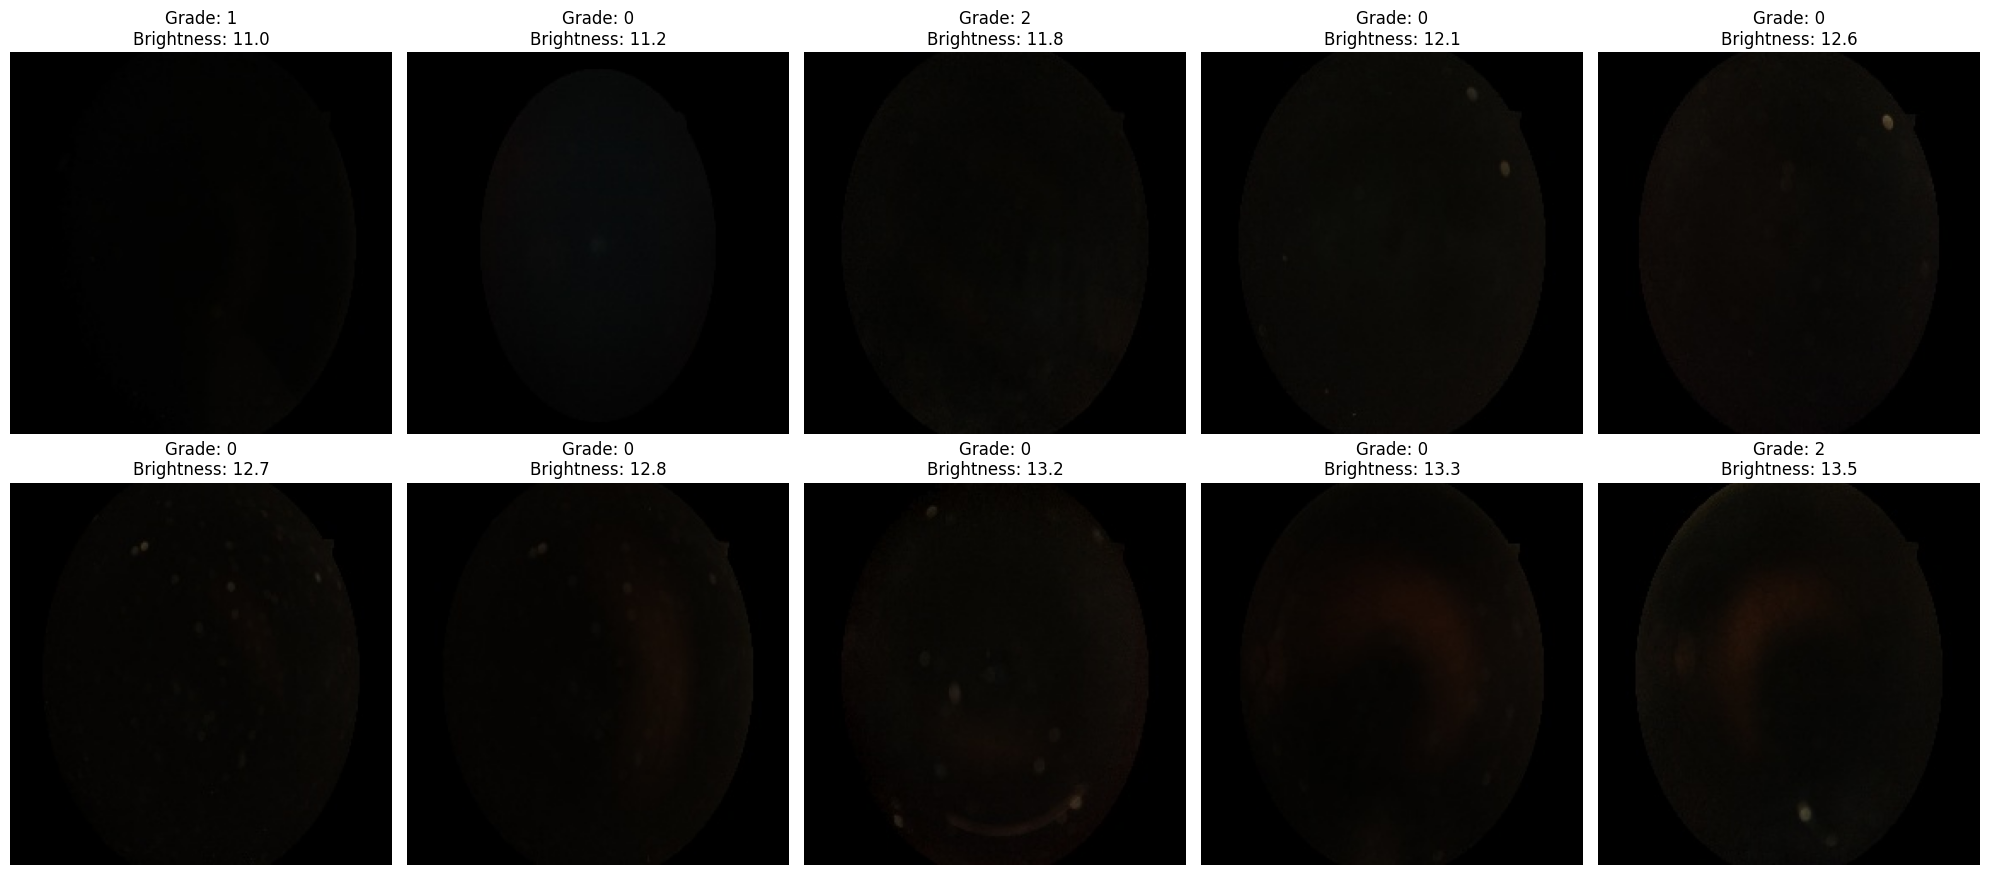

In [74]:
lowest_brightness = retina_quality_df.nsmallest(10, "brightness")

fig, axes = plt.subplots(2, 5, figsize=(20, 9))

for ax, (_, row) in zip(axes.flat, lowest_brightness.iterrows()):

    image = cv2.imread(str(row["image_path"]))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(
        f"Grade: {row['level']}\n"
        f"Brightness: {row['brightness']:.1f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()